In [1]:
from datetime import datetime

import matplotlib.pyplot as mpl
import numpy as np
import pandas as pd
import seaborn as sns

from lds_coding_task.evaluation.metrics import bias, wape

now = datetime.now().strftime("%d/%m/%Y_%H:%M:%S")
print(f"Last notebook execution: {now}")

Last notebook execution: 16/10/2026_05:01:04


In [2]:
# Load all
tables = {
    "df_pedidos_historicos": pd.read_csv(
        "../data/pedidos_historicos_genericos.csv", parse_dates=["fecha_despacho"]
    ),
    "df_pronostico_demanda": pd.read_csv(
        "../data/pronostico_demanda_generico.csv",
        parse_dates=["fecha_emision", "fecha_despacho"],
    ),
}

# Quick profile of each
for name, df in tables.items():
    print(f"\n{'=' * 40}")
    print(f"{name}: {df.shape[0]} rows × {df.shape[1]} cols")
    print(f"  dtypes:\n{df.dtypes}")
    print(f"  nulls: {df.isnull().sum().sum()}")
    print(df.head(3))


df_pedidos_historicos: 1080 rows × 4 cols
  dtypes:
centro_distribucion               str
fecha_despacho         datetime64[us]
unidades_reales               float64
canal_venta                       str
dtype: object
  nulls: 0
  centro_distribucion fecha_despacho  unidades_reales          canal_venta
0            CD_NORTE     2026-01-01          2234.68           PORTAL_WEB
1            CD_NORTE     2026-01-01          1310.74     AGENTE_COMERCIAL
2            CD_NORTE     2026-01-01           266.64  ATENCION_TELEFONICA

df_pronostico_demanda: 1380 rows × 5 cols
  dtypes:
centro_distribucion                  str
fecha_emision             datetime64[us]
fecha_despacho            datetime64[us]
horizonte                            str
unidades_pronosticadas           float64
dtype: object
  nulls: 0
  centro_distribucion fecha_emision fecha_despacho horizonte  \
0           CD_CENTRO    2026-01-01     2026-01-02       D+1   
1           CD_CENTRO    2026-01-02     2026-01-03       D+

#### **Merging: df_pedidos - df_pronosticos**
____

In [3]:
df_pedidos = tables["df_pedidos_historicos"]
df_pronosticos = tables["df_pronostico_demanda"]

print(df_pedidos.columns.tolist())
print(df_pronosticos.columns.tolist())

['centro_distribucion', 'fecha_despacho', 'unidades_reales', 'canal_venta']
['centro_distribucion', 'fecha_emision', 'fecha_despacho', 'horizonte', 'unidades_pronosticadas']


In [4]:
# 1. Aggregate actuals to center × date
actuals = df_pedidos.groupby(["centro_distribucion", "fecha_despacho"], as_index=False)[
    "unidades_reales"
].sum()

# 2. Merge
df_eval = df_pronosticos.merge(
    actuals,
    on=["centro_distribucion", "fecha_despacho"],
    how="inner",
)

# 3. Sanity check — quantify inner-join impact
dropped = len(df_pronosticos) - len(df_eval)
print(f"df_pronosticos: {len(df_pronosticos)} rows")
print(f"df_eval:        {len(df_eval)} rows")
print(f"Dropped by inner join: {dropped} ({dropped / len(df_pronosticos) * 100:.1f}%)")

df_pronosticos: 1380 rows
df_eval:        1380 rows
Dropped by inner join: 0 (0.0%)


In [5]:
dups = df_pronosticos.duplicated(
    subset=["centro_distribucion", "fecha_despacho", "horizonte"]
).sum()
print(f"Duplicate rows: {dups}")

Duplicate rows: 0


In [6]:
# Verify forecast emission dates — confirm horizonte is unambiguous
print("fecha_emision distribution:")
print(df_pronosticos["fecha_emision"].value_counts().sort_index())

fecha_emision distribution:
fecha_emision
2026-01-01    24
2026-01-02    24
2026-01-03    24
2026-01-04    24
2026-01-05    24
2026-01-06    24
2026-01-07    24
2026-01-08    24
2026-01-09    24
2026-01-10    24
2026-01-11    24
2026-01-12    24
2026-01-13    24
2026-01-14    24
2026-01-15    24
2026-01-16    24
2026-01-17    24
2026-01-18    24
2026-01-19    24
2026-01-20    24
2026-01-21    24
2026-01-22    24
2026-01-23    24
2026-01-24    24
2026-01-25    24
2026-01-26    24
2026-01-27    24
2026-01-28    24
2026-01-29    24
2026-01-30    24
2026-01-31    24
2026-02-01    24
2026-02-02    24
2026-02-03    24
2026-02-04    24
2026-02-05    24
2026-02-06    24
2026-02-07    24
2026-02-08    24
2026-02-09    24
2026-02-10    24
2026-02-11    24
2026-02-12    24
2026-02-13    24
2026-02-14    24
2026-02-15    24
2026-02-16    24
2026-02-17    24
2026-02-18    24
2026-02-19    24
2026-02-20    24
2026-02-21    24
2026-02-22    24
2026-02-23    24
2026-02-24    24
2026-02-25    24
2026-0

#### **Métricas por centro y horizonte**
____

In [7]:
results = []
for (center, horizon), group in df_eval.groupby(["centro_distribucion", "horizonte"]):
    real = group["unidades_reales"]
    forecast = group["unidades_pronosticadas"]
    results.append(
        {
            "centro_distribucion": center,
            "horizonte": horizon,
            "WAPE": wape(real, forecast),
            "Bias": bias(real, forecast),
        }
    )

metrics = pd.DataFrame(results)

print("=== WAPE ===")
print(
    metrics.pivot(
        index="centro_distribucion", columns="horizonte", values="WAPE"
    ).round(4)
)
print("\n=== Bias ===")
print(
    metrics.pivot(
        index="centro_distribucion", columns="horizonte", values="Bias"
    ).round(4)
)

=== WAPE ===
horizonte               D+1     D+2     D+3     D+4
centro_distribucion                                
CD_CENTRO            0.1959  0.1949  0.2666  0.2767
CD_ESTE              0.2478  0.2467  0.2543  0.2866
CD_NORTE             0.0884  0.1006  0.0854  0.1188
CD_OESTE             0.2560  0.2407  0.2187  0.2402
CD_PACIFICO          0.2027  0.2108  0.2159  0.2581
CD_SUR               0.3173  0.3233  0.3185  0.3027

=== Bias ===
horizonte               D+1     D+2     D+3     D+4
centro_distribucion                                
CD_CENTRO           -0.1959 -0.1758 -0.2028 -0.2353
CD_ESTE              0.2478  0.2467  0.2490  0.2689
CD_NORTE             0.0851  0.0867  0.0643  0.0621
CD_OESTE            -0.2560 -0.2407 -0.2028 -0.2054
CD_PACIFICO         -0.2027 -0.2068 -0.2084 -0.2464
CD_SUR               0.3173  0.3233  0.3185  0.3027


In [8]:
# Global volume-weighted WAPE per horizon (avoids equal-weight averaging of centers)
global_by_horizon = df_eval.groupby("horizonte").apply(
    lambda g: wape(g["unidades_reales"], g["unidades_pronosticadas"])
)
print("\n=== WAPE global (volume-weighted) ===")
print(global_by_horizon.round(4))


=== WAPE global (volume-weighted) ===
horizonte
D+1    0.1977
D+2    0.2030
D+3    0.2085
D+4    0.2253
dtype: float64


#### **Q1: ¿Qué centros subestiman / sobreestiman de manera consistente?**
____

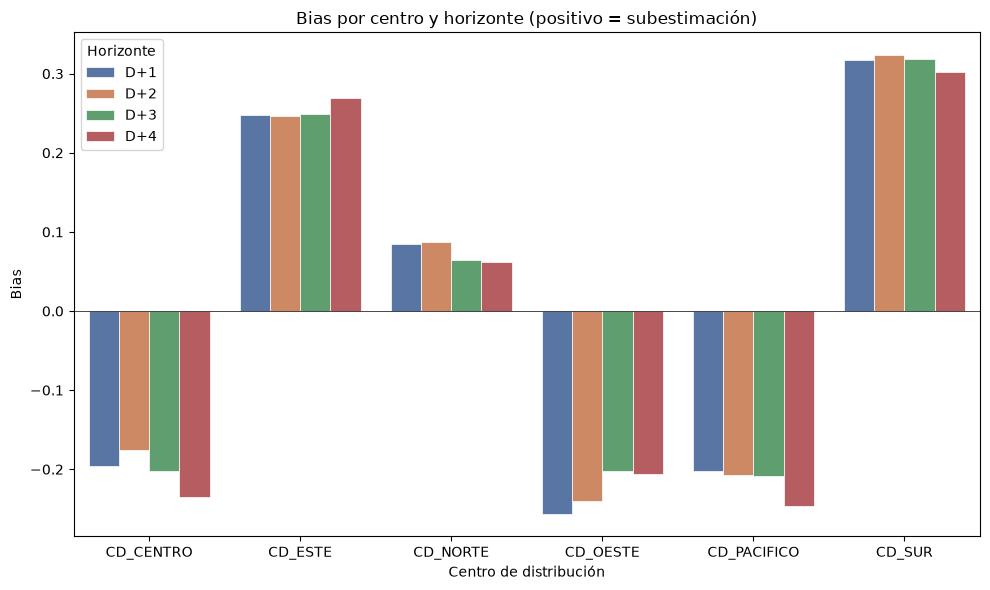

In [9]:
fig, ax = mpl.subplots(figsize=(10, 6))

sns.barplot(
    data=metrics,
    x="centro_distribucion",
    y="Bias",
    hue="horizonte",
    palette="deep",
    order=sorted(metrics["centro_distribucion"].unique()),
    hue_order=["D+1", "D+2", "D+3", "D+4"],
    edgecolor="white",
    linewidth=0.5,
)

ax.axhline(y=0, color="black", linewidth=0.5)
ax.set_xlabel("Centro de distribución")
ax.set_ylabel("Bias")
ax.set_title("Bias por centro y horizonte (positivo = subestimación)")
ax.legend(title="Horizonte")
mpl.tight_layout()
mpl.show()

In [10]:
# Verify CONSISTENCY: does the sign of bias flip across horizons for any center?
sign_consistency = (
    metrics.assign(bias_sign=np.sign(metrics["Bias"]))
    .groupby("centro_distribucion")["bias_sign"]
    .agg(["min", "max", "count"])
)
sign_consistency["consistent"] = sign_consistency["min"] == sign_consistency["max"]
print(sign_consistency)

                     min  max  count  consistent
centro_distribucion                             
CD_CENTRO           -1.0 -1.0      4        True
CD_ESTE              1.0  1.0      4        True
CD_NORTE             1.0  1.0      4        True
CD_OESTE            -1.0 -1.0      4        True
CD_PACIFICO         -1.0 -1.0      4        True
CD_SUR               1.0  1.0      4        True


**A:** Tres centros subestiman la demanda real de manera consistente (Bias > 0 en todos los horizontes): **CD_ESTE**, **CD_NORTE** y **CD_SUR**. Los otros tres — **CD_CENTRO**, **CD_OESTE** y **CD_PACIFICO** — sobreestiman (Bias < 0 en todos los horizontes).

La consistencia se verifica mediante el signo del Bias en cada horizonte: no hay ningún centro donde el signo cambie entre D+1 y D+4, confirmando que la sub/sobreestimación es sistémica y no un artefacto de un solo horizonte.

#### **Q2: ¿Cómo se degrada la precisión (WAPE) de D+1 a D+4?**
____

In [11]:
# Q2: WAPE degradation D+1 → D+4
piv_wape = metrics.pivot(
    index="centro_distribucion", columns="horizonte", values="WAPE"
)
piv_wape["delta[D+4-D+1]"] = piv_wape["D+4"] - piv_wape["D+1"]
print(piv_wape.round(4))

horizonte               D+1     D+2     D+3     D+4  delta[D+4-D+1]
centro_distribucion                                                
CD_CENTRO            0.1959  0.1949  0.2666  0.2767          0.0808
CD_ESTE              0.2478  0.2467  0.2543  0.2866          0.0388
CD_NORTE             0.0884  0.1006  0.0854  0.1188          0.0304
CD_OESTE             0.2560  0.2407  0.2187  0.2402         -0.0159
CD_PACIFICO          0.2027  0.2108  0.2159  0.2581          0.0554
CD_SUR               0.3173  0.3233  0.3185  0.3027         -0.0146


In [12]:
# Volume check: is the "improvement" in CD_OESTE / CD_SUR a denominator artifact?
vol_by_horizon = (
    df_eval.groupby(["centro_distribucion", "horizonte"])["unidades_reales"]
    .agg(["mean", "sum", "count"])
    .unstack()
)
print(vol_by_horizon.round(1))

                       mean                               sum            \
horizonte               D+1     D+2     D+3     D+4       D+1       D+2   
centro_distribucion                                                       
CD_CENTRO            1510.1  1504.7  1503.1  1508.3   89097.7   87274.5   
CD_ESTE               797.3   794.7   795.9   798.4   47038.6   46090.4   
CD_NORTE             3062.2  3063.9  3070.6  3079.1  180672.7  177707.7   
CD_OESTE              491.3   490.5   491.6   492.5   28985.0   28450.9   
CD_PACIFICO           664.1   662.5   662.4   664.2   39179.6   38424.9   
CD_SUR               2221.2  2221.6  2216.9  2224.3  131050.8  128850.7   

                                        count              
horizonte                 D+3       D+4   D+1 D+2 D+3 D+4  
centro_distribucion                                        
CD_CENTRO             85674.5   84467.4    59  58  57  56  
CD_ESTE               45367.3   44712.7    59  58  57  56  
CD_NORTE             175

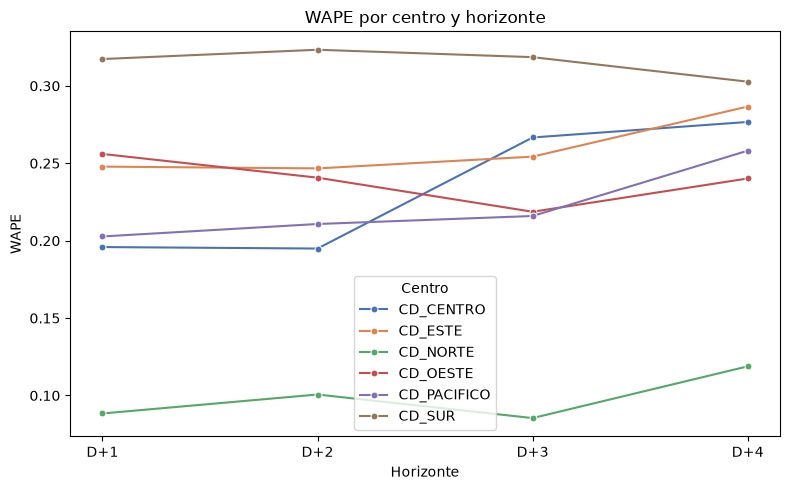

In [14]:
fig, ax = mpl.subplots(figsize=(8, 5))

sns.lineplot(
    data=metrics,
    x="horizonte",
    y="WAPE",
    hue="centro_distribucion",
    palette="deep",
    marker="o",
    linewidth=1.5,
    markersize=5,
    hue_order=sorted(metrics["centro_distribucion"].unique()),
    # order=["D+1", "D+2", "D+3", "D+4"],
)

ax.set_xlabel("Horizonte")
ax.set_ylabel("WAPE")
ax.set_title("WAPE por centro y horizonte")
ax.legend(title="Centro")
mpl.tight_layout()
mpl.show()

In [15]:
# Practical impact: MAE in units per center per horizon
mae_by_center = (
    df_eval.assign(
        abs_err=(df_eval["unidades_reales"] - df_eval["unidades_pronosticadas"]).abs()
    )
    .groupby(["centro_distribucion", "horizonte"])["abs_err"]
    .mean()
    .unstack()
)
print("MAE (unidades) por centro y horizonte:")
print(mae_by_center.round(1))

MAE (unidades) por centro y horizonte:
horizonte              D+1    D+2    D+3    D+4
centro_distribucion                            
CD_CENTRO            295.8  293.3  400.8  417.3
CD_ESTE              197.6  196.0  202.4  228.9
CD_NORTE             270.7  308.3  262.3  365.9
CD_OESTE             125.8  118.1  107.5  118.3
CD_PACIFICO          134.6  139.6  143.0  171.5
CD_SUR               704.8  718.3  706.2  673.3


**A:** En 4 de 6 centros (CD_CENTRO, CD_ESTE, CD_NORTE, CD_PACIFICO) el WAPE aumenta de D+1 a D+4, con un incremento máximo de **+8.1 pp** en CD_CENTRO (0.20 → 0.28). La degradación es progresiva y moderada en general (≤ 8 pp).

En CD_OESTE y CD_SUR el WAPE disminuye levemente (≈ −1.5 pp), lo cual es atípico. Este comportamiento coincide con un volumen real menor en D+4 para esos centros, lo que reduce el denominador de WAPE y puede no reflejar una mejora real del modelo, sino un efecto del volumen.

#### **Limitaciones**
____
- WAPE y Bias se calculan sobre el conjunto completo de fechas; no se segmenta por temporada ni se excluyen outliers (días festivos, promociones).
- El inner join asume que todo pronóstico tiene un real asociado; si hay fechas sin pedidos, se descartan.
- No se evalúa la calibración (intervalos de confianza) del pronóstico, solo el error puntual.
- El WAPE global por horizonte pondera por volumen real, no es un promedio simple de los WAPEs por centro.